# HW4 final test: strategy against the S&P 500 total-return index

**Period:** April 1, 2016 to September 30, 2026. **Starting capital:** $1,000,000 in each portfolio.

This notebook reports the single final-test run of the strategy fixed during development (2010-2015).
It reads the files written by `run_final_test.py`; it does not fit a model or run a backtest itself.

```text
run_final_test.py -> outputs/final_test/ -> this notebook (tables, chart, checks)
```

To reproduce the numbers, run from the repository root, then rerun this notebook:

```text
.venv/Scripts/python.exe Homeworks/HW4/Mauricio_Gutierrez/run_final_test.py
```

## 1. The fixed strategy

Every setting below was chosen on development data before the final test was run.

| Part | Setting |
|---|---|
| Model | Ridge regression, alpha 100, predicting the 90-calendar-day return |
| Features | 21-, 63- and 252-minus-21-session momentum; 63-session volatility; 252-session drawdown; net margin, operating return on assets, debt to assets and cash to assets (each ranked within sector on the date); age of the latest filing |
| Training | First fit on April 1, 2016, then every January 1. Each fit uses only targets whose holding period ended before the fit. Training targets are clipped at the 1st and 99th percentiles of that fit's training rows |
| Data rules | Financial reports are used from the day after filing. A one-day price ratio outside 0.2 to 5 is treated as a data error: dropped from training, and treated as no quote in the backtest |
| Candidates | Members of the entry quarter's universe, limited to the 1,000 largest by the quarterly size rank; the most volatile 20% on the signal date are excluded |
| Decision | After any close with at least 5% of portfolio value in cash and at least 21 sessions since the previous decision |
| Entry | At the next session's close |
| Budget | The smaller of available cash and one third of portfolio value |
| Allocation | 30 stocks, weighted by inverse 63-session volatility; 30% stock cap and 50% sector cap |
| Exit | 90 calendar days after entry, at that close or the next session's |
| Costs | 0.10% of trade value on entry and on exit; cash earns 0% |
| Missing prices | No entry without a quote. A held stock is valued at its last accepted close; if no quote appears within 10 sessions after maturity, the lot is closed at that last close and flagged |

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Lectures/modeling").is_dir())
HW_DIR = ROOT / "Homeworks/HW4/Mauricio_Gutierrez"
RESULTS = HW_DIR / "outputs/final_test"
assert (RESULTS / "performance_comparison.csv").is_file(), "Run run_final_test.py first."

settings = json.loads((RESULTS / "settings.json").read_text(encoding="utf-8"))
PRIMARY, INDEX = settings["primary"], "S&P 500 TR"
INITIAL = settings["config"]["initial_cash"]
table = pd.read_csv(RESULTS / "performance_comparison.csv", index_col="portfolio")
nav = pd.read_csv(RESULTS / "daily_nav.csv", index_col="date", parse_dates=True)
print("Test window:", nav.index[0].date(), "to", nav.index[-1].date(), "-", len(nav), "market sessions")

Test window: 2016-04-01 to 2026-09-30 - 2640 market sessions


## 2. Performance comparison

Both portfolios start with $1,000,000. The benchmark buys `^SP500TR` at the first test close and holds it,
with no fees. The strategy's final value includes cash and the open positions valued at the
September 30, 2026 close. Sharpe uses daily portfolio returns and a 2% annual risk-free rate.

In [2]:
both = table.loc[[PRIMARY, INDEX]]
report = pd.DataFrame({
    "Final value": both.final_value.map("${:,.0f}".format),
    "Total return": both.total_return.map("{:.1%}".format),
    "CAGR": both.CAGR.map("{:.2%}".format),
    "Maximum drawdown": both.max_drawdown.map("{:.1%}".format),
    "Sharpe (2% risk-free)": both.daily_Sharpe.map("{:.3f}".format),
    "Annualized volatility": both.annualized_volatility.map("{:.1%}".format),
}).T
display(report)
primary, index = table.loc[PRIMARY], table.loc[INDEX]
print(f"Strategy final value = cash ${primary.cash_at_end:,.0f} + open positions ${primary.open_positions_at_end:,.0f}"
      f" in {primary.open_lots_at_end:.0f} lots")

portfolio,"Strategy (largest 1,000)",S&P 500 TR
Final value,"$2,661,011","$4,402,747"
Total return,166.1%,340.3%
CAGR,9.77%,15.17%
Maximum drawdown,-36.8%,-33.8%
Sharpe (2% risk-free),0.472,0.773
Annualized volatility,19.8%,17.8%


Strategy final value = cash $47,846 + open positions $2,613,166 in 90 lots


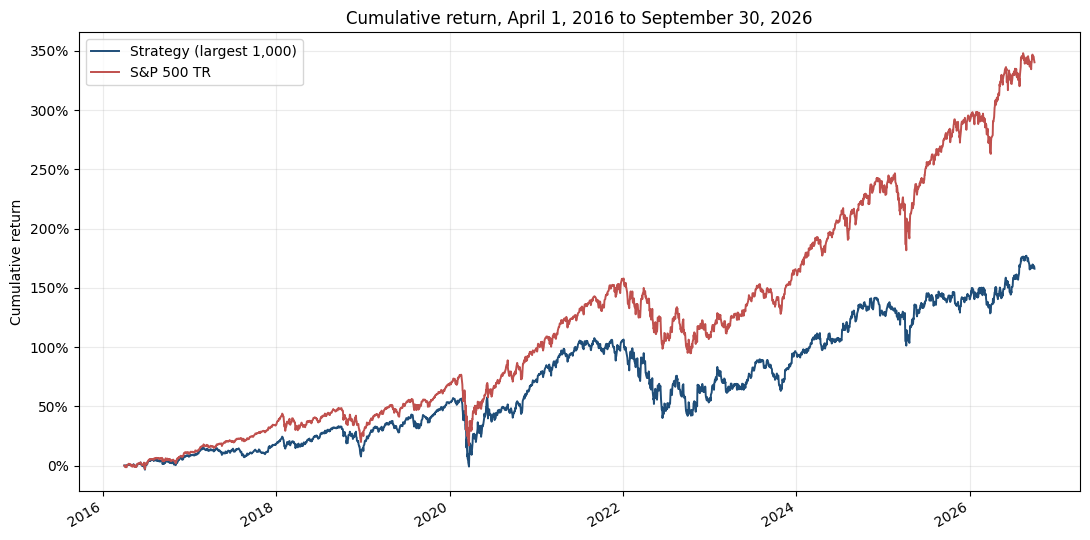

In [3]:
cumulative = nav[[PRIMARY, INDEX]] / INITIAL - 1
fig, ax = plt.subplots(figsize=(11, 5.5))
cumulative.plot(ax=ax, linewidth=1.4, color=["#1f4e79", "#c0504d"])
ax.set_title("Cumulative return, April 1, 2016 to September 30, 2026")
ax.set_ylabel("Cumulative return")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [4]:
gap = primary.final_value - index.final_value
verdict = "beat" if gap > 0 else "did not beat"
display(Markdown(
    f"**The strategy {verdict} the benchmark.** It finished at **${primary.final_value:,.0f}** against "
    f"**${index.final_value:,.0f}**, a difference of **${gap:,.0f}**. "
    f"CAGR was {primary.CAGR:.2%} against {index.CAGR:.2%}, Sharpe {primary.daily_Sharpe:.2f} against "
    f"{index.daily_Sharpe:.2f}, and maximum drawdown {primary.max_drawdown:.1%} against {index.max_drawdown:.1%}."))

**The strategy did not beat the benchmark.** It finished at **$2,661,011** against **$4,402,747**, a difference of **$-1,741,735**. CAGR was 9.77% against 15.17%, Sharpe 0.47 against 0.77, and maximum drawdown -36.8% against -33.8%.

### Returns by calendar year

The first and last rows are partial years (from April 2016, and to September 2026).

In [5]:
year_end = nav[[PRIMARY, INDEX]].groupby(nav.index.year).last()
start_values = pd.concat([pd.DataFrame(INITIAL, index=[year_end.index[0] - 1], columns=year_end.columns), year_end])
yearly = (start_values / start_values.shift(1) - 1).dropna()
yearly["Difference"] = yearly[PRIMARY] - yearly[INDEX]
display(yearly.apply(lambda column: column.map("{:.1%}".format)))
print("Years ahead of the benchmark:", int((yearly.Difference > 0).sum()), "of", len(yearly))

,"Strategy (largest 1,000)",S&P 500 TR,Difference
2016,7.5%,9.8%,-2.3%
2017,9.2%,21.8%,-12.6%
2018,-2.7%,-4.4%,1.7%
2019,33.8%,31.5%,2.3%
2020,13.0%,18.4%,-5.4%
2021,18.6%,28.7%,-10.1%
2022,-24.1%,-18.1%,-6.0%
2023,25.8%,26.3%,-0.5%
2024,16.6%,25.0%,-8.4%
2025,5.4%,17.9%,-12.5%


Years ahead of the benchmark: 2 of 11


## 3. Accounting and timing checks

Three kinds of evidence: a purchase that can be verified by hand, the full ledger recomputed from the
trade log, and the timing checks saved by the run.

In [6]:
trades = pd.read_csv(RESULTS / "primary/trades.csv", parse_dates=["signal_date", "entry_date", "due_date", "date"])
daily = pd.read_csv(RESULTS / "primary/daily.csv", parse_dates=["date"])
open_lots = pd.read_csv(RESULTS / "primary/open_lots.csv", parse_dates=["entry_date", "due_date"])
decisions = pd.read_csv(RESULTS / "primary/decisions.csv", parse_dates=["signal_date", "execution_date"])
fee_rate = settings["config"]["fee_rate"]

# One lot by hand: the first purchase and its sale.
buy = trades.loc[trades.side.eq("BUY")].iloc[0]
sell = trades.loc[trades.side.eq("SELL") & trades.lot_id.eq(buy.lot_id)].iloc[0]
first = decisions.iloc[0]
print(f"Decision after the close of {first.signal_date.date()}: cash ${first.cash:,.2f}, portfolio value ${first.nav:,.2f}")
print(f"  budget = min(cash, value / 3) = ${min(first.cash, first.nav / 3):,.2f}  (logged ${first.budget_cap:,.2f})")
print(f"Lot {buy.lot_id}: {buy.symbol}, bought {buy.entry_date.date()} at {buy.entry_price:.4f}")
print(f"  cash spent ${buy.cash_cost:,.2f} = shares value ${buy.notional:,.2f} + fee ${buy.fee:,.2f}")
print(f"  check: value = cash / 1.001 = ${buy.cash_cost / (1 + fee_rate):,.2f}; fee = value x 0.001 = ${buy.notional * fee_rate:,.2f}")
print(f"  units = value / price = {buy.notional / buy.entry_price:,.4f}  (logged {buy.units:,.4f})")
print(f"  due = entry + 90 days = {(buy.entry_date + pd.Timedelta(days=90)).date()} ({(buy.entry_date + pd.Timedelta(days=90)).day_name()});"
      f" sold {sell.date.date()} at {sell.price:.4f}")
print(f"  proceeds = units x price - fee = ${buy.units * sell.price * (1 - fee_rate):,.2f}  (logged ${sell.cash_change:,.2f})")
print(f"  profit after both fees = ${sell.cash_change - buy.cash_cost:,.2f}  (logged ${sell.net_pnl:,.2f})")
assert np.isclose(buy.notional, buy.cash_cost / (1 + fee_rate)) and np.isclose(buy.units, buy.notional / buy.entry_price)
assert np.isclose(sell.cash_change, buy.units * sell.price * (1 - fee_rate)) and buy.entry_date > buy.signal_date

Decision after the close of 2016-04-01: cash $1,000,000.00, portfolio value $1,000,000.00
  budget = min(cash, value / 3) = $333,333.33  (logged $333,333.33)
Lot 1: ALGT, bought 2016-04-04 at 155.0300
  cash spent $8,723.30 = shares value $8,714.59 + fee $8.71
  check: value = cash / 1.001 = $8,714.59; fee = value x 0.001 = $8.71
  units = value / price = 56.2123  (logged 56.2123)
  due = entry + 90 days = 2016-07-03 (Sunday); sold 2016-07-05 at 129.8100
  proceeds = units x price - fee = $7,289.62  (logged $7,289.62)
  profit after both fees = $-1,433.69  (logged $-1,433.69)


In [7]:
# The whole ledger, recomputed here from the trade log.
flows = trades.groupby("date").cash_change.sum().reindex(daily.date, fill_value=0.0)
rebuilt_cash = INITIAL + flows.cumsum().to_numpy()
sold = set(trades.loc[trades.side.eq("SELL"), "lot_id"])
bought = set(trades.loc[trades.side.eq("BUY"), "lot_id"])
ledger = pd.Series({
    "Daily cash equals $1,000,000 plus all trade cash flows": np.allclose(rebuilt_cash, daily.cash, atol=1e-6),
    "Cash is never negative (no borrowing, no cash spent twice)": daily.cash.min() >= -1e-7,
    "Portfolio value equals cash plus holdings every day": np.allclose(daily.nav, daily.cash + daily.holdings_value, atol=1e-6),
    "Every lot is sold at most once": not trades.loc[trades.side.eq("SELL"), "lot_id"].duplicated().any(),
    "Lots bought and not sold are exactly the open lots": bought - sold == set(open_lots.lot_id),
    "Final value equals cash plus open lots at the last close": np.isclose(daily.nav.iloc[-1], daily.cash.iloc[-1] + open_lots.market_value.sum()),
    "Every purchase fits inside its decision's budget": (decisions.planned_cash <= decisions.budget_cap + 1e-7).all(),
    "No trade is dated after September 30, 2026": trades.date.max() <= pd.Timestamp("2026-09-30"),
}).map({True: "PASS", False: "FAIL"})
display(ledger.to_frame("Result"))
assert ledger.eq("PASS").all()

saved = pd.read_csv(RESULTS / "accounting_and_timing_checks.csv").set_index("portfolio").T
display(saved[[PRIMARY]].rename(columns={PRIMARY: "Saved by the run"}))
assert saved.eq("PASS").all().all()

,Result
"Daily cash equals $1,000,000 plus all trade cash flows",PASS
"Cash is never negative (no borrowing, no cash spent twice)",PASS
Portfolio value equals cash plus holdings every day,PASS
Every lot is sold at most once,PASS
Lots bought and not sold are exactly the open lots,PASS
Final value equals cash plus open lots at the last close,PASS
Every purchase fits inside its decision's budget,PASS
"No trade is dated after September 30, 2026",PASS


portfolio,Saved by the run
cash_and_nav,PASS
fees_and_lots,PASS
maturities,PASS
budget,PASS
first decision is the first test session,PASS
every entry is the session after its signal,PASS
no trade or mark after the test end,PASS
every sale is on or after 90 calendar days,PASS
"every sale is the first session on or after maturity, unless waiting for a quote",PASS
open lots mature after the test end or await a quote,PASS


### Data gaps

No fill is invented. A held stock without a usable quote is valued at its last accepted close and flagged.
The stress row reruns the same strategy with every forced no-quote exit worth zero.

In [8]:
gaps = pd.Series({
    "Purchases": f"{primary.purchases:,.0f}",
    "Sales": f"{primary.sales:,.0f}",
    "Orders cancelled for a missing entry quote": f"{primary.cancelled_orders:,.0f}",
    "Lot-sessions valued at a last accepted close": f"{primary.flagged_valuations:,.0f}",
    "Lots closed by the no-quote rule": f"{primary.no_quote_exits:,.0f}",
    "Daily quotes rejected by the suspect-price rule": f"{primary.suspect_quotes_removed:,.0f}",
    "Sessions with an exposure limit breached": f"{primary.exposure_breach_sessions:,.0f}",
    "Fees paid": f"${primary.fees_paid:,.0f}",
    "Average cash weight": f"{primary.average_cash_weight:.1%}",
    "Final value if no-quote exits were worth zero": f"${table.loc['Stress: no-quote exits worth zero', 'final_value']:,.0f}",
})
display(gaps.to_frame("Primary strategy"))

,Primary strategy
Purchases,"3,750"
Sales,"3,660"
Orders cancelled for a missing entry quote,0
Lot-sessions valued at a last accepted close,151
Lots closed by the no-quote rule,3
Daily quotes rejected by the suspect-price rule,"48,746"
Sessions with an exposure limit breached,0
Fees paid,"$138,407"
Average cash weight,4.1%
Final value if no-quote exits were worth zero,"$2,582,853"


## 4. Sensitivity to the size filter

My first idea was to trade only the largest 10% of companies (200 stocks). In development I compared
the largest 1,000, 500 and 200, and the largest 1,000 had the best Sharpe, so it became the strategy.
The other cutoffs were declared as sensitivity checks before the final test. They are shown for
information and do not replace the reported result.

,final_value,CAGR,max_drawdown,annualized_volatility,daily_Sharpe
portfolio,,,,,
"Strategy (largest 1,000)","$2,661,011",9.77%,-36.8%,19.8%,0.472
Sensitivity: largest 500,"$3,092,494",11.36%,-34.8%,18.2%,0.576
Sensitivity: largest 200,"$3,389,605",12.33%,-31.4%,16.5%,0.668
"Sensitivity: all 2,000","$1,869,155",6.14%,-41.1%,21.2%,0.295
S&P 500 TR,"$4,402,747",15.17%,-33.8%,17.8%,0.773


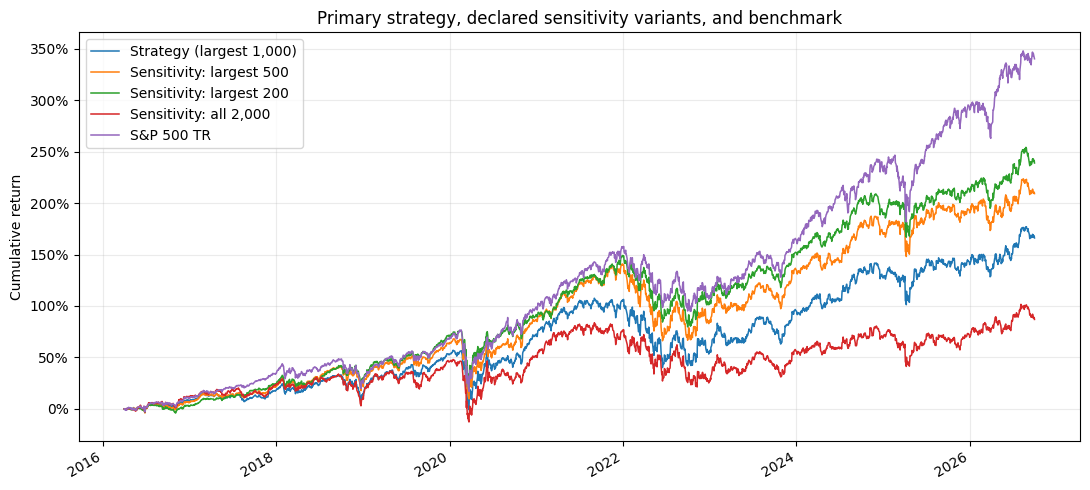

In [9]:
order = [PRIMARY, "Sensitivity: largest 500", "Sensitivity: largest 200", "Sensitivity: all 2,000", INDEX]
sensitivity = table.loc[order, ["final_value", "CAGR", "max_drawdown", "annualized_volatility", "daily_Sharpe"]]
formats = {"final_value": "${:,.0f}", "CAGR": "{:.2%}", "max_drawdown": "{:.1%}",
           "annualized_volatility": "{:.1%}", "daily_Sharpe": "{:.3f}"}
display(pd.DataFrame({name: sensitivity[name].map(text.format) for name, text in formats.items()}))
fig, ax = plt.subplots(figsize=(11, 5))
(nav[order] / INITIAL - 1).plot(ax=ax, linewidth=1.1)
ax.set_title("Primary strategy, declared sensitivity variants, and benchmark")
ax.set_ylabel("Cumulative return")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 5. Did the model rank stocks?

Rank IC is the correlation, on each date, between the forecast order and the realized 90-day return order.
A useful signal shows a small positive value in most periods. Each row is one fit and the dates it forecast.

In [10]:
scores = pd.read_csv(RESULTS / "model_scores.csv")
splits = pd.read_csv(RESULTS / "training_splits.csv")
model = scores[["fit_date", "mean_daily_rank_IC", "R2", "scored_rows"]].merge(
    splits[["fit_date", "training_rows", "last_training_outcome"]], on="fit_date")
formats = {"mean_daily_rank_IC": "{:+.3f}", "R2": "{:+.3f}", "scored_rows": "{:,.0f}", "training_rows": "{:,.0f}"}
shown = model.copy()
for name, text in formats.items():
    shown[name] = shown[name].map(text.format)
display(shown.set_index("fit_date"))
assert (pd.to_datetime(model.last_training_outcome) < pd.to_datetime(model.fit_date)).all()
print(f"Average rank IC across fits: {scores.mean_daily_rank_IC.mean():+.4f}; "
      f"positive in {int((scores.mean_daily_rank_IC > 0).sum())} of {len(scores)} fits")
print("Every fit's last training outcome is before its fit date: PASS")

,mean_daily_rank_IC,R2,scored_rows,training_rows,last_training_outcome
fit_date,,,,,
2016-04-01,-0.010,-0.050,"379,513","2,959,875",2016-03-30
2017-01-01,-0.014,-0.010,"498,533","3,335,087",2016-12-29
2018-01-01,+0.037,-0.033,"498,290","3,833,845",2017-12-28
2019-01-01,+0.020,-0.015,"499,869","4,336,312",2018-12-31
2020-01-01,-0.022,-0.050,"499,985","4,834,477",2019-12-31
2021-01-01,-0.012,-0.027,"492,497","5,334,923",2020-12-31
2022-01-01,-0.090,-0.123,"488,890","5,827,184",2021-12-30
2023-01-01,+0.025,-0.003,"489,209","6,315,488",2022-12-29
2024-01-01,-0.031,-0.008,"491,043","6,804,748",2023-12-28


Average rank IC across fits: -0.0062; positive in 5 of 11 fits
Every fit's last training outcome is before its fit date: PASS


## 6. Findings

**Result.** The strategy did not beat the benchmark. It roughly multiplied the capital by 2.7 while the
index multiplied it by 4.4, with a slightly larger drawdown and higher volatility.

**Why.**

- **The model does not rank stocks.** Rank IC averages about zero and changes sign between fits, as it did
  in development. The selection of 30 stocks is therefore close to arbitrary within the screened candidates.
- **The benchmark was hard to match in this decade.** The index is weighted by company size, and the very
  largest companies led the market. A portfolio of 30 inverse-volatility-weighted stocks from the largest
  1,000 holds little of them. The sensitivity table shows the same thing: the stricter the size filter,
  the closer to the index.
- **Costs.** Reinvesting every 90 days cost about $138,000 in fees.
- **The development result was optimistic.** On 2013-2015 this strategy had a Sharpe of 1.00 against 0.95
  for the index. That did not carry over, partly because the cutoff was the best of three I tried.

**Risks taken.** Concentration in 90 open lots, a 90-day holding rule with no stop, no hedge against market
falls (the drawdown in 2020 was as deep as the index's), and exposure to mid-sized companies.

**Limitations.**

- Sector labels are a current snapshot, not a history, and the size rank is a proxy that contains errors.
- Financial data is a restated vendor snapshot; it may differ from what was known at the time.
- The suspect-price rule also removes a genuine one-day move beyond the bounds, and keeps a stock unquoted
  until its price returns within them.
- Fees are an assumption; there is no slippage or market impact, and shares are fractional.

**What I would try next.**

- Test each feature alone with decile sorts before putting it in the model, and keep only those with a
  consistent effect.
- Model the tails directly (indicator features for the top and bottom groups, or a non-linear model),
  since the strategy only trades the top of the ranking.
- Predict the return relative to the index instead of the raw return.
- Add value features once market capitalization can be verified; it is missing in 96% of the reports.
- Hold more names or weight by size to reduce the gap to a size-weighted benchmark.